# **Detecção de Anomalias com Isolation Forest**
## Investigação de Técnica de Machine Learning: **Isolation Forest (Detecção de Anomalias)**

---
* **Disciplina:** Aprendizado de Máquina I
* **Professor:** Mateus Guilherme Fuini

**Aluna:** Michelle de Sales Silva

---

### Sumário
1. **Introdução** (1.1 Aplicações práticas)
2. **Fundamentação teórica**
3. **Dataset sintético**
4. **Experimento 1: efeito dos parâmetros**
5. **Experimento 2: Isolation Forest vs outros detectores**
6. **Dataset real: Breast Cancer Wisconsin**
7. **Análise crítica**
8. **Conclusão**
9. **Referências**
10. **Declaração de uso de Inteligência Artificial**

## **1. Introdução**

Isolation Forest é um algoritmo de detecção de anomalias não supervisionado, proposto por Liu, Ting e Zhou (2008). A ideia central é simples: anomalias são poucas e diferentes, então são mais fáceis de isolar do que pontos normais.

Em vez de modelar o comportamento “normal” dos dados (como fazem K-Means e One-Class SVM), o algoritmo constrói várias árvores com cortes aleatórios e mede quantos cortes são necessários para isolar cada ponto. Pontos isolados com poucos cortes tendem a ser anomalias.
<br><br>
**Problema que resolve:** identificar observações raras e suspeitas em dados onde quase tudo é normal e, muitas vezes, não há rótulos disponíveis.
<br><br>

**Por que usar o Isolation Forest?**
Na prática, quase nunca temos uma base com os casos anômalos já marcados. Fraudes, falhas e comportamentos fora do padrão são raros e, muitas vezes, só descobertos depois que o problema acontece. O Isolation Forest é interessante porque resolve esse cenário: ele não precisa de rótulos nem de suposições sobre a distribuição dos dados, e foca em encontrar o que é raro, em vez de descrever o que é normal.
<br><br>
### **1.1 Aplicações práticas**

- **Fraude financeira:** transações com valor, horário ou frequência muito diferentes do histórico do cliente.
- **Manutenção preditiva:** leituras de sensores que fogem do padrão e podem indicar uma falha antes da parada de uma máquina.
- **Segurança de redes:** acessos e tráfego incomuns que podem indicar uma intrusão.
- **Controle de qualidade:** peças ou lotes com medidas fora do esperado em um processo de produção.
- **Monitoramento de operações e CRM:** picos ou quedas atípicas em volumes de envios, atendimentos ou demandas, que podem apontar erro de processo ou algo que merece atenção.
- **Preparação de dados:** identificar outliers antes de treinar outros modelos, evitando que eles distorçam o resultado.

##**2. Fundamentação teórica**
**2.1 Ideia central**

Anomalias são poucas e diferentes dos demais pontos. Por isso, ao dividir o espaço de forma aleatória, elas ficam sozinhas (isoladas) com poucos cortes, enquanto pontos normais, que estão no meio de regiões densas, precisam de muitos cortes.
<br><br>
**2.2 Como o algoritmo funciona**

1.  Sorteia uma subamostra dos dados (max_samples).
2.  Constrói uma árvore de isolamento (iTree): a cada nó, escolhe um atributo aleatório e um valor de corte aleatório entre o mínimo e o máximo desse atributo.
3. Repete até isolar cada ponto ou atingir a profundidade máxima.
4. Repete o processo para várias árvores (n_estimators), formando a floresta.
5. Para cada ponto, calcula o comprimento médio do caminho h(x) da raiz até o nó onde ele foi isolado.

Caminho curto = provável anomalia. Caminho longo = provável ponto normal.
<br><br>

**2.3 Score de anomalia**

$$s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}}$$
<br><br>

* **E[h(x)]:** comprimento médio do caminho de x nas árvores.

* **c(n):** comprimento médio esperado de um caminho em uma árvore de busca binária com n pontos. Serve para normalizar o score, de modo que ele não dependa do tamanho da amostra.
<br>
$$c(n) = 2H(n-1) - \frac{2(n-1)}{n}, \quad H(i) \approx \ln(i) + 0{,}5772$$
<br><br>

**Interpretação:**

* s próximo de 1: provável anomalia
* s bem menor que 0,5: provável ponto normal
* s próximo de 0,5 para todos: dados sem anomalias claras

<br><br>
**2.4 Principais parâmetros (scikit-learn)**

`n_estimators`:	Número de árvores. Mais árvores deixam o score mais estável, com custo maior de processamento.

`max_samples`:	Tamanho da subamostra de cada árvore (padrão: 256). Subamostras pequenas funcionam bem e deixam o algoritmo rápido.

`contamination`:	Proporção esperada de anomalias. Só define o limiar de corte, não altera os scores.

`max_features`:	Fração de atributos sorteados por árvore.

`random_state`:	Reprodutibilidade, já que o algoritmo é aleatório.
<br><br>

**2.5 Características importantes**

* **Não supervisionado:** treina sem rótulos.
* Não usa distância nem densidade, ao contrário de K-Means e LOF.
* Complexidade linear em relação ao número de amostras, por causa da subamostragem.
* Não assume distribuição dos dados.

## **3. Dataset sintético**

Para visualizar o comportamento do algoritmo, criei um dataset **fictício** em 2D, inspirado em uma base de cadastro de microempreendedores individuais (MEI). **Nenhum dado real foi utilizado.**

- **faturamento_mensal:** faturamento médio mensal do MEI (R$).
- **tempo_abertura:** tempo de atividade do MEI (em meses).

São 1000 registros:
- **950 normais**, em dois perfis: MEIs iniciantes (faturamento baixo, pouco tempo de abertura) e MEIs consolidados (faturamento maior, mais tempo de abertura).
- **50 anomalias (5%)**, com combinações incompatíveis entre faturamento e tempo de abertura, que podem indicar erro de cadastro ou casos que merecem atenção.

Como os dados são sintéticos, eu conheço os rótulos verdadeiros. O Isolation Forest **não usa** esses rótulos para treinar, e eles servem apenas para avaliar o resultado depois.

In [1]:
#imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

SEED = 42

In [2]:
#geração dos dados

rng = np.random.RandomState(SEED)

n_total = 1000
proporcao_anomalias = 0.05
n_anom = int(n_total * proporcao_anomalias)
n_norm = n_total - n_anom

# Registros normais: dois perfis de MEI
# [faturamento_mensal (R$), tempo_abertura (meses)]
X_norm, _ = make_blobs(
    n_samples=n_norm,
    centers=[[1500, 12], [5000, 60]],
    cluster_std=[[400, 6], [900, 15]],
    random_state=SEED
)
X_norm = np.clip(X_norm, 0, None)

# Anomalias: combinações espalhadas pelo espaço
X_anom = np.column_stack([
    rng.uniform(0, 15000, n_anom),   # faturamento
    rng.uniform(0, 120, n_anom)      # tempo de abertura
])

# Junta tudo (y: 0 = normal, 1 = anomalia)
X = np.vstack([X_norm, X_anom])
y = np.r_[np.zeros(n_norm), np.ones(n_anom)].astype(int)

# Embaralha
idx = rng.permutation(len(X))
X, y = X[idx], y[idx]

X[:, 0] = X[:, 0].round(2)   # faturamento em R$ (centavos)
X[:, 1] = X[:, 1].round()    # tempo em meses inteiros

df = pd.DataFrame(X, columns=["faturamento_mensal", "tempo_abertura_meses"])
df["anomalia"] = y

print(df["anomalia"].value_counts())
df.head()

anomalia
0    950
1     50
Name: count, dtype: int64


,faturamento_mensal,tempo_abertura_meses,anomalia
0,4675.67,63.0,1
1,1511.33,12.0,0
2,3593.71,52.0,0
3,2285.89,12.0,0
4,1311.23,19.0,0


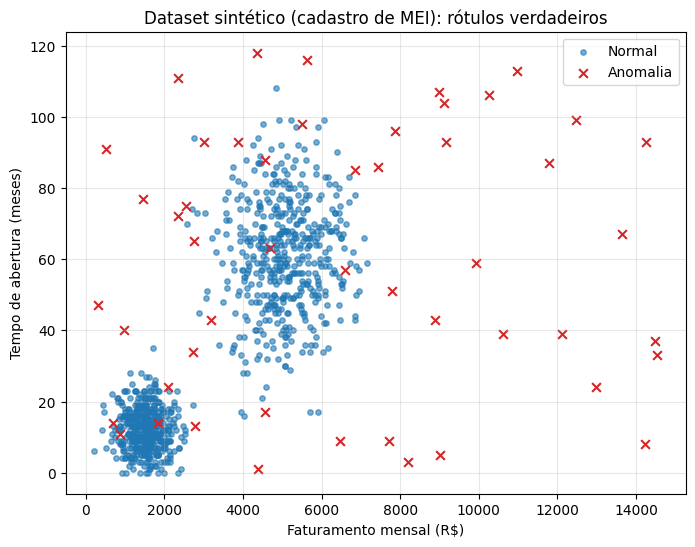

In [3]:
# visu
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=15, c="tab:blue", alpha=0.6, label="Normal")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=40, c="tab:red", marker="x", label="Anomalia")
plt.title("Dataset sintético (cadastro de MEI): rótulos verdadeiros")
plt.xlabel("Faturamento mensal (R$)")
plt.ylabel("Tempo de abertura (meses)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

> **Observação:** Como as anomalias (marcadas com `X` em vermelho) foram geradas de forma uniforme em todo o espaço de atributos (*Faturamento mensal* $\times$ *Tempo de abertura*), alguns pontos anômalos acabaram sobrepostos aos dois agrupamentos de perfis normais de MEI. Esse comportamento é intencional: em cenários reais, nem toda anomalia apresenta valores extremos isolados. Como o **Isolation Forest** depende da baixa densidade para isolar pontos com poucas divisões, essas anomalias camufladas exigem caminhos mais longos nas árvores e tendem a gerar falsos negativos, impondo um limite natural ao *recall* do modelo.

## **4. Experimento 1: efeito dos parâmetros**

O objetivo é entender como cada parâmetro afeta o resultado. Como tenho os rótulos verdadeiros, avalio o modelo com métricas de classificação, lembrando que ele **não** usa esses rótulos no treino.

Métricas:
- **Precision:** dos pontos marcados como anomalia, quantos realmente eram.
- **Recall:** das anomalias reais, quantas foram encontradas.
- **F1:** equilíbrio entre Precision e Recall.
- **ROC-AUC e PR-AUC:** avaliam o **score** do modelo, sem depender de um limiar. Como a base é desbalanceada (5% de anomalias), a PR-AUC é a mais informativa.
- A **acurácia** entra só para mostrar que engana: um modelo que chamasse tudo de "normal" já teria 95%.

In [4]:
##imports e função de avaliação

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay)

def avaliar(model, X, y):
    """Treina sem rótulos e avalia com os rótulos verdadeiros."""
    model.fit(X)
    y_pred = (model.predict(X) == -1).astype(int)   # -1 = anomalia -> 1
    score = -model.score_samples(X) # maior = mais anômalo

    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "roc_auc": roc_auc_score(y, score),
        "pr_auc": average_precision_score(y, score),
    }, y_pred

# Baseline: "tudo normal"
print("Acurácia de um modelo que chama tudo de normal:", accuracy_score(y, np.zeros_like(y)))

Acurácia de um modelo que chama tudo de normal: 0.95


### 4.1 Variação do contamination

Comparo `contamination` = 1%, 5% (valor real) e 10%. Em teoria, esse parâmetro **só define o limiar de corte** e não muda os scores. Por isso, espero **ROC-AUC e PR-AUC iguais** nos três casos, e Precision, Recall e F1 diferentes.

In [5]:
contaminacoes = [0.01, 0.05, 0.10]
linhas, preds = [], {}

for c in contaminacoes:
    modelo = IsolationForest(n_estimators=100, contamination=c, random_state=SEED)
    metricas, y_pred = avaliar(modelo, X, y)
    metricas["contamination"] = c
    linhas.append(metricas)
    preds[c] = (modelo, y_pred)

tabela_cont = pd.DataFrame(linhas).set_index("contamination").round(3)
tabela_cont

,accuracy,precision,recall,f1,roc_auc,pr_auc
contamination,,,,,,
0.01,0.960,1.00,0.20,0.333,0.946,0.81
0.05,0.976,0.76,0.76,0.760,0.946,0.81
0.10,0.934,0.42,0.84,0.560,0.946,0.81


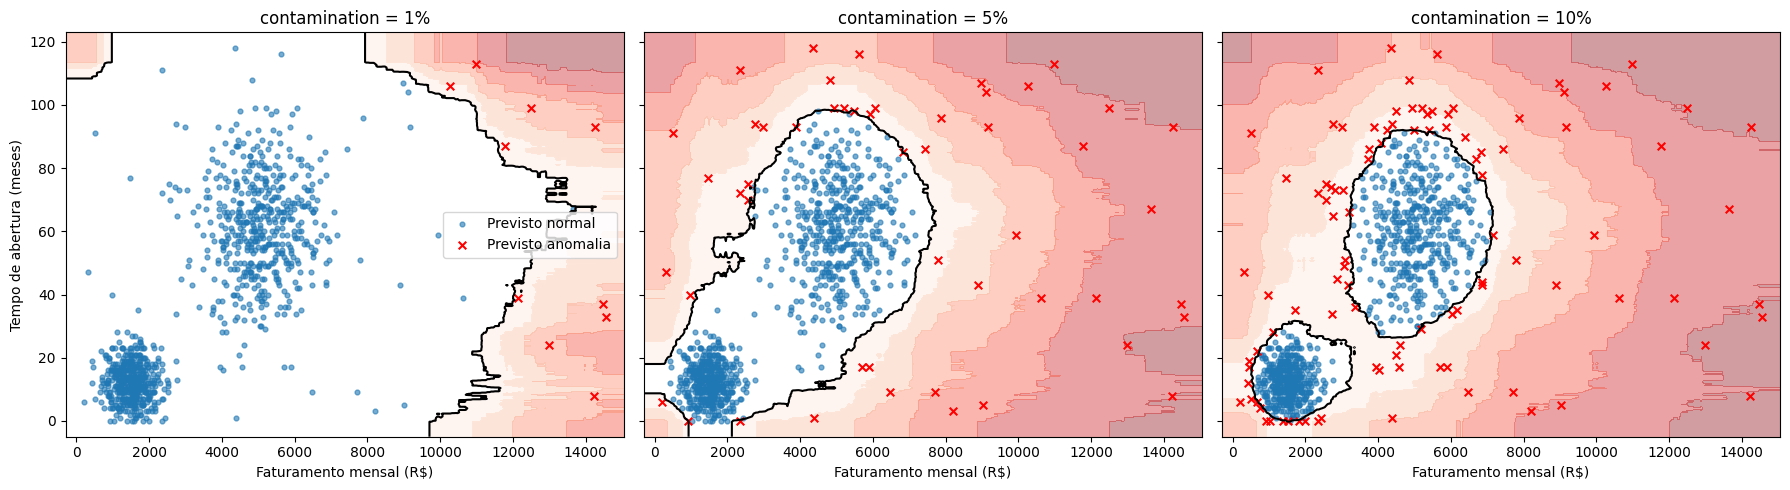

In [6]:
#grafico e fronteira de decisão

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 500, X[:, 0].max() + 500, 300),
    np.linspace(X[:, 1].min() - 5, X[:, 1].max() + 5, 300)
)
grade = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, c in zip(axes, contaminacoes):
    modelo, y_pred = preds[c]
    Z = modelo.decision_function(grade).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 7), cmap="Reds_r", alpha=0.4)
    ax.contour(xx, yy, Z, levels=[0], colors="black", linewidths=1.5)
    ax.scatter(X[y_pred == 0, 0], X[y_pred == 0, 1], s=12, c="tab:blue", alpha=0.6, label="Previsto normal")
    ax.scatter(X[y_pred == 1, 0], X[y_pred == 1, 1], s=30, c="red", marker="x", label="Previsto anomalia")
    ax.set_title(f"contamination = {c:.0%}")
    ax.set_xlabel("Faturamento mensal (R$)")
axes[0].set_ylabel("Tempo de abertura (meses)")
axes[0].legend()
plt.tight_layout()
plt.show()

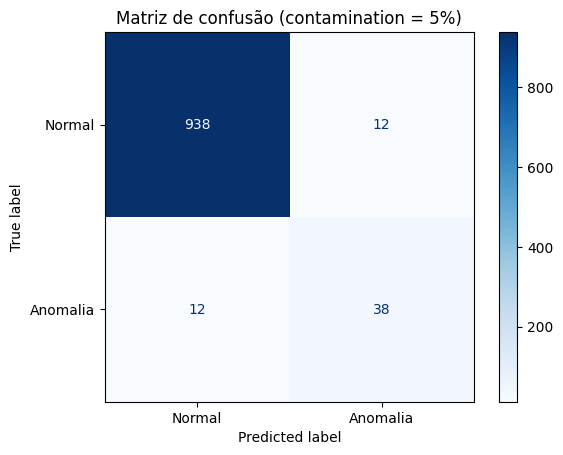

In [7]:
#Matriz de confusão

_, y_pred_5 = preds[0.05]
ConfusionMatrixDisplay(confusion_matrix(y, y_pred_5),
display_labels=["Normal", "Anomalia"]).plot(cmap="Blues")
plt.title("Matriz de confusão (contamination = 5%)")
plt.show()

### Interpretação: contamination e matriz de confusão

**Scores idênticos:** o ROC-AUC (0,946) e o PR-AUC (0,81) foram iguais para 1%, 5% e 10%, confirmando que o `contamination` não altera o modelo nem os scores de anomalia, apenas o limiar usado para classificar um ponto como anomalia. Já Precision, Recall e F1 mudaram bastante.

**Trade-off Precision × Recall:** com 1%, o modelo foi muito conservador (Precision 1,00, Recall 0,20): tudo o que marcou era anomalia, mas 40 das 50 anomalias passaram despercebidas. Com 10%, ocorreu o oposto (Recall 0,84, Precision 0,42): o modelo encontrou mais anomalias, mas gerou muitos alarmes falsos. O melhor equilíbrio foi com 5% (F1 = 0,76), que coincide com a proporção real de anomalias. Na prática, essa proporção geralmente não é conhecida, então a escolha do `contamination` depende do custo de cada tipo de erro: se deixar passar uma anomalia é mais grave, vale um valor maior.

**Acurácia:** os valores (0,93 a 0,98) ficaram próximos dos 0,95 que um modelo que classifica tudo como normal alcançaria. Com 1%, a acurácia foi de 0,96 mesmo detectando só 20% das anomalias. Por isso, em bases desbalanceadas, Precision, Recall, F1 e PR-AUC são mais adequados.

**Matriz de confusão (5%):** o modelo acertou 38 das 50 anomalias e perdeu 12 (falsos negativos), além de gerar 12 falsos positivos. Mesmo com 10%, 8 anomalias não foram detectadas. Isso confirma a hipótese da seção 3: as anomalias sorteadas dentro dos perfis normais de MEI são "camufladas", porque estão em regiões densas e exigem muitos cortes para serem isoladas, o que impõe um limite ao recall.

### **4.2 Variação de `n_estimators` e `max_samples`**

Como o algoritmo é aleatório, repito cada configuração com 5 sementes diferentes e apresento a média e o desvio-padrão. Uso `contamination=0.05`.

In [8]:
def varrer(param, valores, n_seeds=5):
    resultados = []
    for v in valores:
        rodadas = []
        for s in range(n_seeds):
            modelo = IsolationForest(contamination=0.05, random_state=s, **{param: v})
            m, _ = avaliar(modelo, X, y)
            rodadas.append(m)
        df_r = pd.DataFrame(rodadas)
        resumo = {param: v}
        for col in ["f1", "roc_auc", "pr_auc"]:
            resumo[f"{col}_media"] = df_r[col].mean()
            resumo[f"{col}_dp"] = df_r[col].std()
        resultados.append(resumo)
    return pd.DataFrame(resultados)

res_trees = varrer("n_estimators", [10, 50, 100, 200, 500])
res_samples = varrer("max_samples", [32, 64, 128, 256, 512, len(X)])

display(res_trees.round(3))
display(res_samples.round(3))

,n_estimators,f1_media,f1_dp,roc_auc_media,roc_auc_dp,pr_auc_media,pr_auc_dp
0,10,0.679,0.023,0.940,0.003,0.747,0.026
1,50,0.716,0.026,0.942,0.003,0.789,0.017
2,100,0.724,0.026,0.945,0.001,0.799,0.010
3,200,0.732,0.039,0.945,0.003,0.800,0.012
4,500,0.736,0.009,0.945,0.001,0.802,0.004


,max_samples,f1_media,f1_dp,roc_auc_media,roc_auc_dp,pr_auc_media,pr_auc_dp
0,32,0.644,0.038,0.918,0.011,0.706,0.034
1,64,0.700,0.028,0.934,0.005,0.762,0.017
2,128,0.732,0.011,0.942,0.002,0.789,0.008
3,256,0.724,0.026,0.945,0.001,0.799,0.010
4,512,0.708,0.030,0.945,0.002,0.802,0.009
5,1000,0.704,0.022,0.944,0.001,0.803,0.008


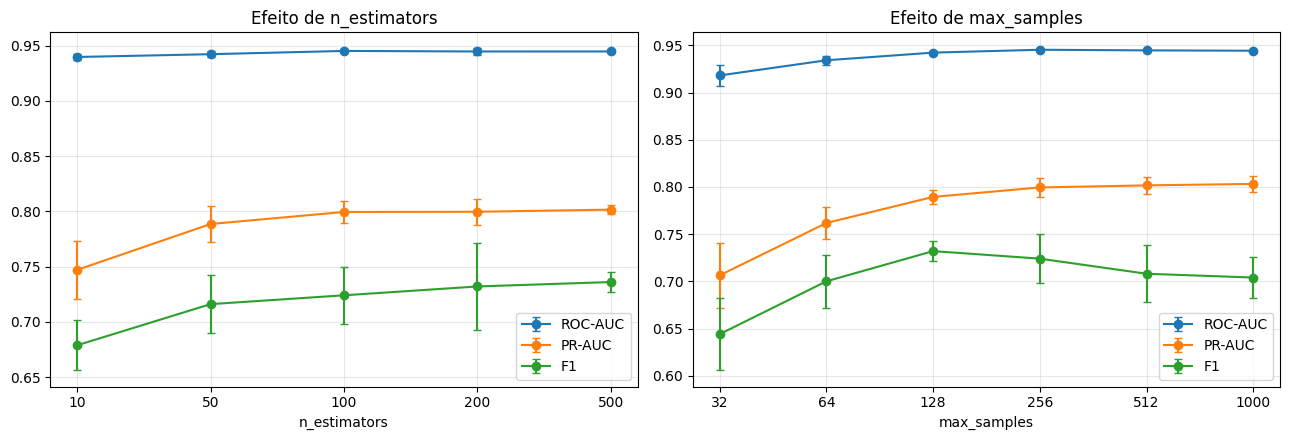

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, res, param in zip(axes, [res_trees, res_samples], ["n_estimators", "max_samples"]):
    for col, nome in [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("f1", "F1")]:
        ax.errorbar(range(len(res)), res[f"{col}_media"], yerr=res[f"{col}_dp"], marker="o", capsize=3, label=nome)
    ax.set_xticks(range(len(res)))
    ax.set_xticklabels(res[param])
    ax.set_xlabel(param)
    ax.set_title(f"Efeito de {param}")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### Interpretação: n_estimators e max_samples

**n_estimators:** o ROC-AUC praticamente não mudou (de 0,940 com 10 árvores para 0,945 com 500). O PR-AUC, mais sensível em bases desbalanceadas, subiu de 0,747 para cerca de 0,80 e estabilizou a partir de 100 árvores, indicando que, a partir desse ponto, mais árvores só aumentam o custo computacional. O F1 continuou crescendo levemente, mas com desvio-padrão irregular, pois depende do limiar de corte e é mais sensível a pequenas mudanças nos scores.

**max_samples:** subamostras muito pequenas (32) prejudicaram o modelo, com menor PR-AUC (0,706) e maior variação entre sementes, pois cada árvore enxerga poucos exemplos dos perfis normais. A partir de 256 os AUCs estabilizaram, e usar a base inteira (1000) não trouxe ganho. O F1 teve seu melhor valor com 128 e caiu levemente com amostras maiores, mas a diferença está dentro do desvio-padrão e não permite concluir que haja piora real. Isso é coerente com a proposta do algoritmo: a subamostragem é suficiente e deixa o treino rápido.

## 5. Experimento 2: Isolation Forest vs outros detectores

Aqui comparo o Isolation Forest com três abordagens de detecção de anomalias baseadas em ideias diferentes:

- **Local Outlier Factor (LOF):** compara a densidade local de um ponto com a de seus vizinhos.
- **One-Class SVM:** aprende uma fronteira em volta dos dados "normais" (versão não supervisionada do SVM).
- **K-Means + distância ao centroide:** o K-Means não é um detector de anomalias, mas pode ser usado como baseline: quanto mais longe do centroide do seu cluster, mais anômalo é o ponto.

**Critério justo de comparação:** cada modelo gera um score de anomalia, e em todos marco como anomalia os 5% de pontos com maior score. Assim, todos têm o mesmo limiar e a diferença vem só da qualidade do score.

**Pré-processamento:** como LOF, One-Class SVM e K-Means usam distância, padronizei os atributos com `StandardScaler` (faturamento em milhares de R$ e tempo em meses têm escalas muito diferentes). O Isolation Forest sorteia cortes em um atributo por vez, então não precisa de padronização e usa os dados originais.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.cluster import KMeans

CONT = 0.05

# Dados padronizados (p os modelos baseados em distância)
X_pad = StandardScaler().fit_transform(X)

In [11]:
scores = {}

# 1) Isolation Forest (dados originais)
iso = IsolationForest(n_estimators=100, random_state=SEED).fit(X)
scores["Isolation Forest"] = -iso.score_samples(X)

# 2) LOF (dados padronizados)
lof = LocalOutlierFactor(n_neighbors=20).fit(X_pad)
scores["LOF"] = -lof.negative_outlier_factor_

# 3) One-Class SVM (dados padronizados); nu ~ fração esperada de anomalias
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=CONT).fit(X_pad)
scores["One-Class SVM"] = -ocsvm.decision_function(X_pad)

# 4) K-Means + distância ao centroide mais próximo (k = 2 perfis)
km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X_pad)
scores["K-Means + distância"] = km.transform(X_pad).min(axis=1)

# Regra única: os 5% de maior score viram anomalia
def classificar_top(score, prop=CONT):
    limiar = np.quantile(score, 1 - prop)
    return (score >= limiar).astype(int)

preds2 = {nome: classificar_top(s) for nome, s in scores.items()}

for nome, p in preds2.items():
    print(f"{nome:22s} -> pontos marcados como anomalia: {p.sum()}")

Isolation Forest       -> pontos marcados como anomalia: 50
LOF                    -> pontos marcados como anomalia: 50
One-Class SVM          -> pontos marcados como anomalia: 50
K-Means + distância    -> pontos marcados como anomalia: 50


In [12]:
#tab métricas
linhas = []
for nome in scores:
    p, s = preds2[nome], scores[nome]
    linhas.append({
        "modelo": nome,
        "precision": precision_score(y, p),
        "recall": recall_score(y, p),
        "f1": f1_score(y, p),
        "roc_auc": roc_auc_score(y, s),
        "pr_auc": average_precision_score(y, s),
    })

tabela_comp = pd.DataFrame(linhas).set_index("modelo").round(3)
tabela_comp.sort_values("pr_auc", ascending=False)

,precision,recall,f1,roc_auc,pr_auc
modelo,,,,,
Isolation Forest,0.76,0.76,0.76,0.946,0.810
LOF,0.72,0.72,0.72,0.945,0.796
K-Means + distância,0.72,0.72,0.72,0.927,0.772
One-Class SVM,0.64,0.64,0.64,0.860,0.683


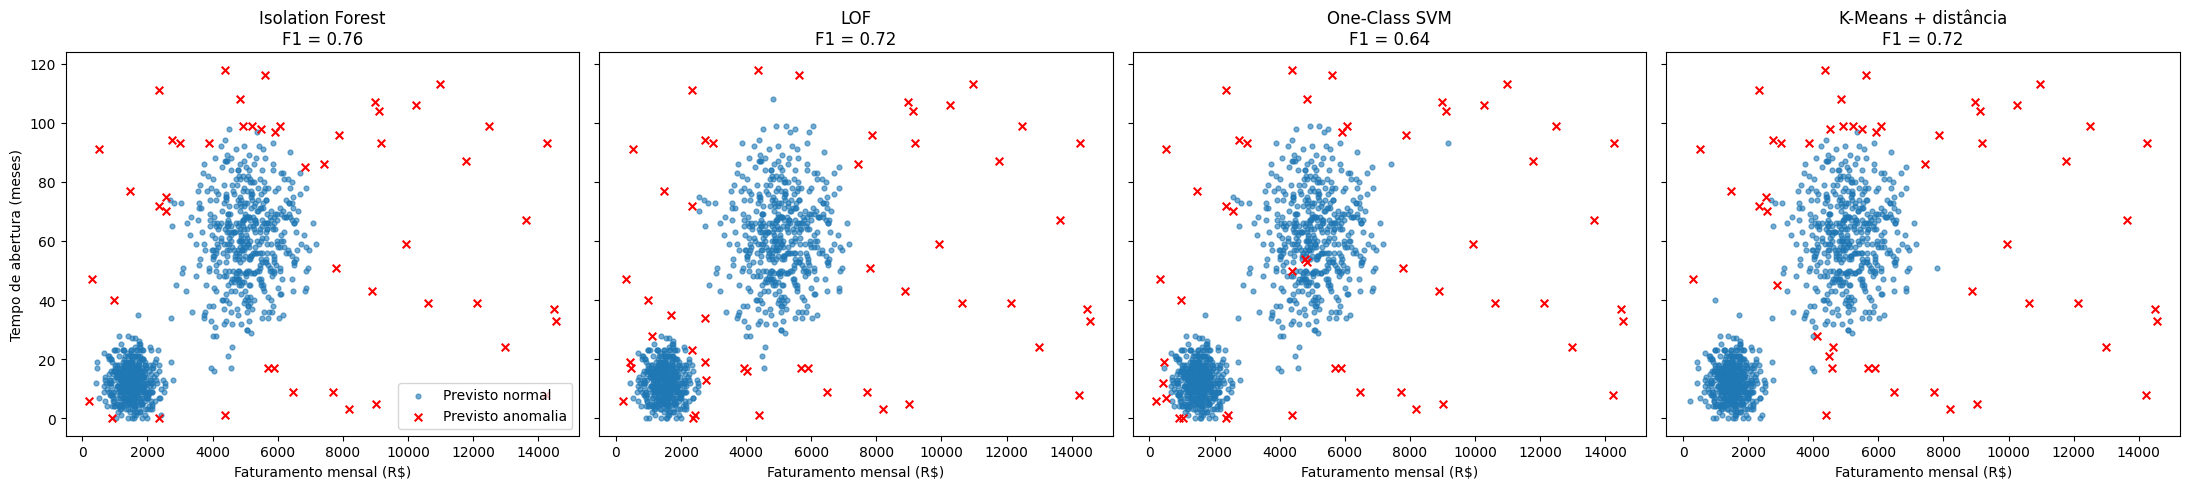

In [13]:
#gráficos lado a lado
fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
for ax, nome in zip(axes, scores):
    p = preds2[nome]
    ax.scatter(X[p == 0, 0], X[p == 0, 1], s=12, c="tab:blue", alpha=0.6, label="Previsto normal")
    ax.scatter(X[p == 1, 0], X[p == 1, 1], s=30, c="red", marker="x", label="Previsto anomalia")
    ax.set_title(f"{nome}\nF1 = {f1_score(y, p):.2f}")
    ax.set_xlabel("Faturamento mensal (R$)")
axes[0].set_ylabel("Tempo de abertura (meses)")
axes[0].legend()
plt.tight_layout()
plt.show()

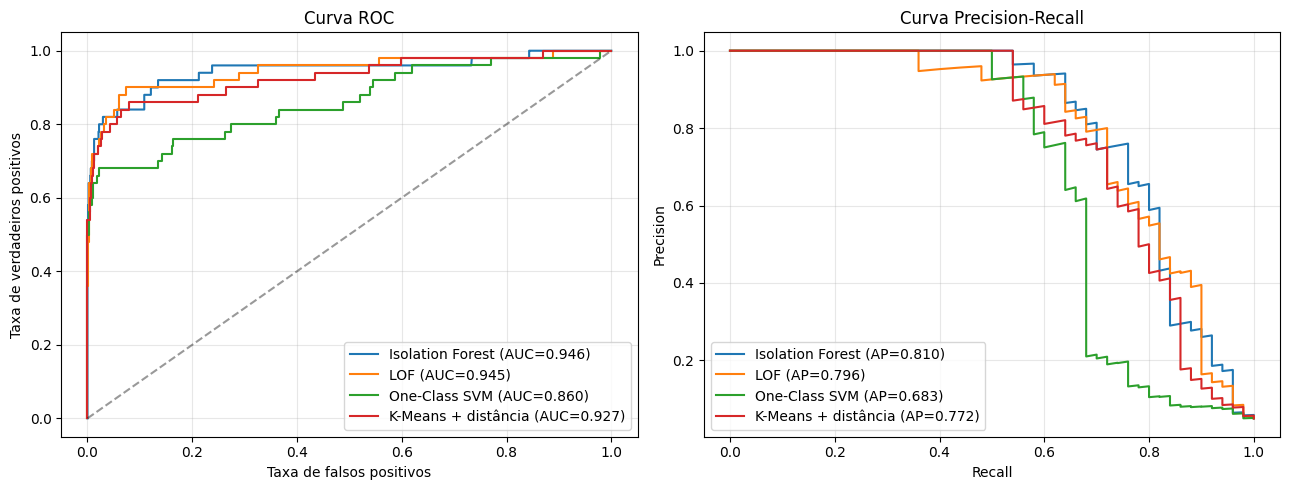

In [14]:
#curvas ROC e Precision-Recall
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome, s in scores.items():
    fpr, tpr, _ = roc_curve(y, s)
    prec, rec, _ = precision_recall_curve(y, s)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y, s):.3f})")
    axes[1].plot(rec, prec, label=f"{nome} (AP={average_precision_score(y, s):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(title="Curva ROC", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
axes[1].set(title="Curva Precision-Recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### **Interpretação**
Nesta base, o Isolation Forest teve o maior F1 (0,76) e PR-AUC (0,810), seguido do LOF (F1 = 0,72; PR-AUC = 0,796), do K-Means + distância (F1 = 0,72; PR-AUC = 0,772) e do One-Class SVM (F1 = 0,64; PR-AUC = 0,683). Como todos os modelos marcaram 50 pontos, Precision, Recall e F1 coincidem em cada um, e a comparação mais informativa é a dos scores (ROC-AUC e PR-AUC).

As diferenças entre os três primeiros são pequenas (equivalem a poucas anomalias) e vêm de uma única base e de uma única semente, então não permitem concluir qual é melhor. Para verificar isso, repeti a comparação com 10 bases diferentes na seção 5.1.

### **5.1 Robustez: repetindo a comparação com 10 bases diferentes**

Para verificar se o resultado não foi sorte de uma única base, repito a comparação com 10 datasets sintéticos gerados com sementes diferentes (mesma receita: 950 normais + 50 anomalias). Em cada um, os quatro modelos marcam os 5% de maior score, e apresento a média e o desvio-padrão das métricas.

In [15]:
def gerar_base(seed, n_total=1000, prop=0.05):
    rng = np.random.RandomState(seed)
    n_a = int(n_total * prop)
    n_n = n_total - n_a
    Xn, _ = make_blobs(n_samples=n_n, centers=[[1500, 12], [5000, 60]],
                       cluster_std=[[400, 6], [900, 15]], random_state=seed)
    Xn = np.clip(Xn, 0, None)
    Xa = np.column_stack([rng.uniform(0, 15000, n_a), rng.uniform(0, 120, n_a)])
    Xb = np.vstack([Xn, Xa])
    yb = np.r_[np.zeros(n_n), np.ones(n_a)].astype(int)
    return Xb, yb

def comparar(seed):
    Xb, yb = gerar_base(seed)
    Xp = StandardScaler().fit_transform(Xb)
    sc = {
        "Isolation Forest": -IsolationForest(n_estimators=100, random_state=seed).fit(Xb).score_samples(Xb),
        "LOF": -LocalOutlierFactor(n_neighbors=20).fit(Xp).negative_outlier_factor_,
        "One-Class SVM": -OneClassSVM(kernel="rbf", gamma="scale", nu=CONT).fit(Xp).decision_function(Xp),
        "K-Means + distância": KMeans(n_clusters=2, n_init=10, random_state=seed).fit(Xp).transform(Xp).min(axis=1),
    }
    linhas = []
    for nome, s in sc.items():
        p = classificar_top(s)
        linhas.append({"seed": seed, "modelo": nome,
                       "f1": f1_score(yb, p),
                       "roc_auc": roc_auc_score(yb, s),
                       "pr_auc": average_precision_score(yb, s)})
    return linhas

todas = [l for seed in range(10) for l in comparar(seed)]
df_rob = pd.DataFrame(todas)

resumo = (df_rob.groupby("modelo")[["f1", "roc_auc", "pr_auc"]]
          .agg(["mean", "std"]).round(3)
          .sort_values(("pr_auc", "mean"), ascending=False))
resumo

f1        roc_auc        pr_auc       
                      mean    std    mean    std   mean    std
modelo                                                        
Isolation Forest     0.724  0.050   0.955  0.016  0.797  0.044
K-Means + distância  0.726  0.057   0.953  0.016  0.792  0.048
One-Class SVM        0.628  0.029   0.887  0.016  0.657  0.036
LOF                  0.630  0.068   0.928  0.026  0.656  0.068

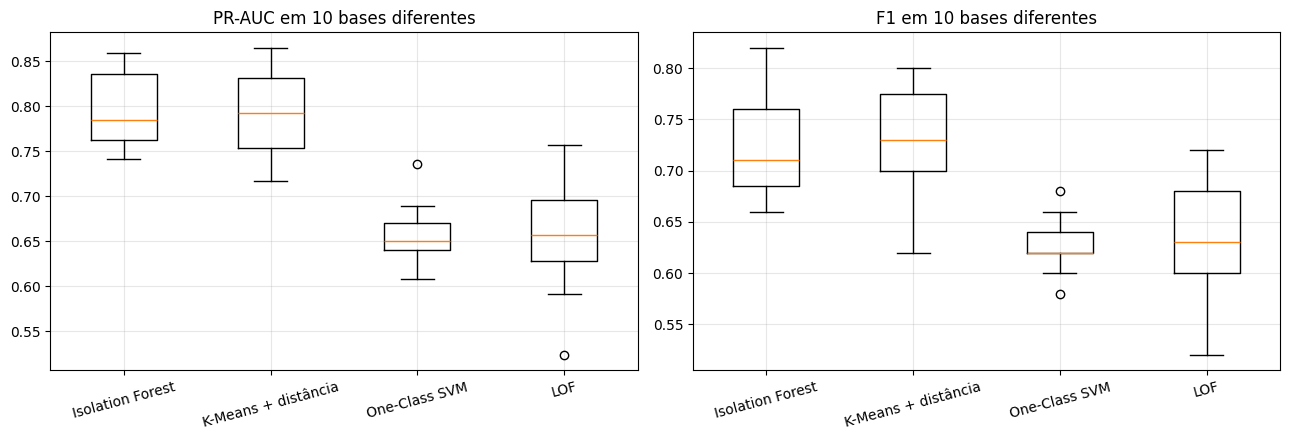

In [16]:
ordem = resumo.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, met, nome in zip(axes, ["pr_auc", "f1"], ["PR-AUC", "F1"]):
    dados = [df_rob[df_rob.modelo == m][met] for m in ordem]
    ax.boxplot(dados, tick_labels=ordem)
    ax.set_title(f"{nome} em 10 bases diferentes")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### **Interpretação da robustez**

Na média de 10 bases, o Isolation Forest (F1 = 0,724; PR-AUC = 0,797) e o K-Means + distância (F1 = 0,726; PR-AUC = 0,792) ficaram empatados no topo: a diferença é muito menor que o desvio-padrão (~0,05), e os boxplots se sobrepõem. O One-Class SVM (F1 = 0,628) e o LOF (F1 = 0,630) ficaram bem abaixo, e o LOF foi o mais instável entre as bases (desvio-padrão de 0,068 no F1).

Isso corrige a impressão da primeira comparação (semente 42), em que o LOF parecia próximo do Isolation Forest. Em uma única base, a diferença entre modelos pode ser fruto do acaso, e por isso foi importante repetir o experimento.

**Por que o K-Means foi tão bem:** o dataset tem dois grupos compactos e arredondados, e eu informei k=2. É o cenário ideal para o K-Means, e a vantagem do Isolation Forest (não precisar saber o número de grupos nem assumir seu formato) não é testada aqui. Esse empate pode não se manter em dados reais, com grupos de formatos irregulares e k desconhecido.

**Limitações:** nenhum modelo teve hiperparâmetros ajustados (LOF com `n_neighbors=20`, One-Class SVM com `nu=0,05` e `gamma="scale"`), então o resultado vale para esses valores e não define o melhor que cada modelo pode alcançar. Os dados são sintéticos, em 2D.

## **6. Dataset real: Breast Cancer Wisconsin**

Para testar o Isolation Forest fora do cenário sintético, usei o dataset **Breast Cancer Wisconsin** (disponível no scikit-learn): 30 atributos numéricos calculados a partir de imagens de exames de células.

**Adaptação para detecção de anomalias:** o dataset original é de classificação (benigno × maligno). Considerei os **casos benignos como normais (357)** e sorteei **19 casos malignos (~5%) como anomalias**. Os rótulos não são usados no treino, apenas na avaliação.

**Atenção:** é uma adaptação, e não um caso de anomalia "natural": os casos malignos não são necessariamente outliers, e podem formar um grupo próprio. Isso afeta os resultados e será discutido na análise crítica.

**Procedimento:** como a escolha dos 19 casos malignos influencia o resultado, repito o experimento com 10 sorteios diferentes. Os modelos são os mesmos do Experimento 2, com os 5% de maior score marcados como anomalia. Para o K-Means, o número de clusters **não é conhecido**, então escolho k entre 2 e 6 pelo Silhouette Score.

In [17]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import silhouette_score

dados = load_breast_cancer()
X_all, y_all = dados.data, dados.target       # 0 = maligno, 1 = benigno
X_ben = X_all[y_all == 1]
X_mal = X_all[y_all == 0]

print("Atributos:", X_all.shape[1])
print("Benignos:", len(X_ben), "| Malignos disponíveis:", len(X_mal))

def montar_base(seed, prop=0.05):
    rng = np.random.RandomState(seed)
    n_a = int(round(len(X_ben) * prop / (1 - prop)))
    idx = rng.choice(len(X_mal), n_a, replace=False)
    Xr = np.vstack([X_ben, X_mal[idx]])
    yr = np.r_[np.zeros(len(X_ben)), np.ones(n_a)].astype(int)
    return Xr, yr

Xr, yr = montar_base(SEED)
print("Base montada:", Xr.shape, "| anomalias:", yr.sum(), f"({yr.mean():.1%})")

Atributos: 30
Benignos: 357 | Malignos disponíveis: 212
Base montada: (376, 30) | anomalias: 19 (5.1%)


In [18]:
def comparar_real(seed):
    Xr, yr = montar_base(seed)
    Xp = StandardScaler().fit_transform(Xr)
    prop = yr.mean()

    # K-Means: k desconhecido, escolhido pelo Silhouette
    melhor_k = max(range(2, 7), key=lambda k: silhouette_score(
        Xp, KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(Xp)))
    km = KMeans(n_clusters=melhor_k, n_init=10, random_state=seed).fit(Xp)

    sc = {
        "Isolation Forest": -IsolationForest(n_estimators=100, random_state=seed).fit(Xr).score_samples(Xr),
        "LOF": -LocalOutlierFactor(n_neighbors=20).fit(Xp).negative_outlier_factor_,
        "One-Class SVM": -OneClassSVM(kernel="rbf", gamma="scale", nu=0.05).fit(Xp).decision_function(Xp),
        "K-Means + distância": km.transform(Xp).min(axis=1),
    }
    linhas = []
    for nome, s in sc.items():
        p = classificar_top(s, prop)
        linhas.append({"seed": seed, "modelo": nome, "k_kmeans": melhor_k,
                       "precision": precision_score(yr, p),
                       "recall": recall_score(yr, p),
                       "f1": f1_score(yr, p),
                       "roc_auc": roc_auc_score(yr, s),
                       "pr_auc": average_precision_score(yr, s)})
    return linhas

df_real = pd.DataFrame([l for s in range(10) for l in comparar_real(s)])

resumo_real = (df_real.groupby("modelo")[["f1", "roc_auc", "pr_auc"]]
               .agg(["mean", "std"]).round(3)
               .sort_values(("pr_auc", "mean"), ascending=False))
display(resumo_real)

print("k escolhido pelo Silhouette em cada sorteio:",
      df_real[df_real.modelo == "K-Means + distância"]["k_kmeans"].tolist())

f1        roc_auc        pr_auc       
                      mean    std    mean    std   mean    std
modelo                                                        
Isolation Forest     0.568  0.054   0.946  0.019  0.587  0.040
LOF                  0.458  0.127   0.930  0.021  0.447  0.092
K-Means + distância  0.432  0.074   0.912  0.026  0.404  0.081
One-Class SVM        0.247  0.086   0.895  0.026  0.258  0.045

k escolhido pelo Silhouette em cada sorteio: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


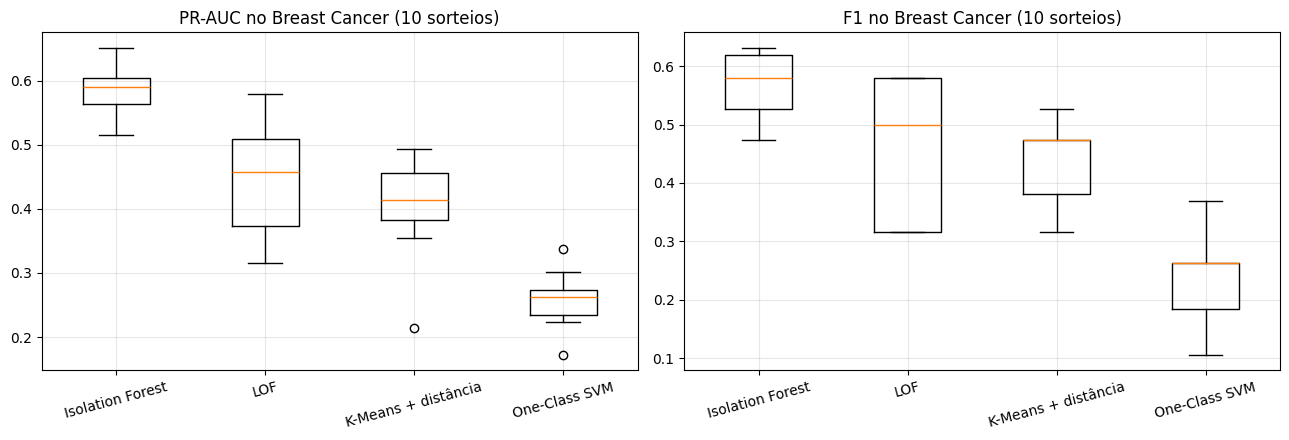

In [19]:
ordem = resumo_real.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, met, nome in zip(axes, ["pr_auc", "f1"], ["PR-AUC", "F1"]):
    dados_box = [df_real[df_real.modelo == m][met] for m in ordem]
    ax.boxplot(dados_box, tick_labels=ordem)
    ax.set_title(f"{nome} no Breast Cancer (10 sorteios)")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **7. Análise crítica**

### **7.1 Vantagens observadas**

- **Dispensa rótulos e definição de k:** o Isolation Forest foi treinado sem utilizar as classes e sem estipular o número de grupos, ao contrário do K-Means, que exigiu o valor de k (informado no cenário sintético e escolhido via Silhouette no real).
- **Desempenho consistente:** manteve-se no topo em PR-AUC nos dois cenários. No sintético, empatou com o K-Means + distância (PR-AUC de 0,797 contra 0,792), enquanto no Breast Cancer (30 atributos) ficou claramente à frente (0,587 contra 0,447 do LOF e 0,404 do K-Means).
- **Baixa sensibilidade a `n_estimators` e `max_samples`:** os AUCs estabilizaram a partir de 100 árvores e subamostras de 256, o que mantém o treinamento leve.
- **Independência de padronização:** como o algoritmo sorteia cortes por atributo, utilizei os dados originais, ao passo que LOF, One-Class SVM e K-Means exigiram o uso de `StandardScaler`.

### **7.2 Limitações**

**Observadas neste trabalho:**
- **Escolha do `contamination`:** o parâmetro apenas define o limiar, mas altera bastante o resultado (Recall de 0,20 com 1% e Precision de 0,42 com 10%). Em bases reais, a proporção exata de anomalias é desconhecida.
- **Anomalias camufladas:** pontos anômalos inseridos em regiões densas não são isolados e geram falsos negativos (8 anomalias permaneceram sem detecção mesmo com 10%).
- **Desempenho inferior nos dados reais:** F1 próximo de 0,57, já que os casos malignos não constituem outliers "naturais" e apresentam sobreposição com os benignos.
- **Avaliação na própria base:** os modelos foram treinados e avaliados sobre o mesmo conjunto de dados.
- **Ausência de ajuste de hiperparâmetros:** nenhum algoritmo passou por otimização, de modo que as comparações refletem apenas os valores adotados.
- **Escopo dos dados:** apenas uma base sintética em 2D e uma real adaptada (19 casos malignos sorteados como anomalias), com 10 repetições cada, o que impede generalizar os resultados para qualquer cenário.


### **7.3 Diferenças em relação ao que foi abordado na disciplina**

- **K-Means:** agrupa os dados pela proximidade a centroides e depende da escolha de k e da escala; além disso, outliers deslocam esses centroides. Já o Isolation Forest não forma grupos: ele atribui um score de anomalia. Nos experimentos, o K-Means atuou como baseline (distância ao centroide) e teve bom desempenho no cenário ideal, mas ficou atrás nos dados reais.
- **SVM:** a versão vista em aula é supervisionada, utilizando rótulos de classe. O One-Class SVM é a variante não supervisionada, aprende uma fronteira ao redor dos dados normais, mostra-se sensível a `nu` e `gamma` e obteve o pior resultado nos dois cenários.
- **Avaliação de modelos:** os mesmos conceitos (Precision, Recall, F1, matriz de confusão) continuam válidos, mas em bases desbalanceadas a acurácia pode enganar e o PR-AUC torna-se mais informativo.
- **Redes Bayesianas:** modelam dependências probabilísticas entre variáveis e requerem uma estrutura probabilística; o Isolation Forest, por sua vez, não assume nenhuma distribuição.

## **8. Conclusão**

Neste trabalho explorei o Isolation Forest, um detector de anomalias não supervisionado que isola pontos raros por meio de cortes aleatórios. Os experimentos indicaram que:

1. O `contamination` não modifica os scores (mantendo ROC-AUC e PR-AUC idênticos), apenas ajusta o limiar e define o equilíbrio entre Precision e Recall.
2. Valores de `n_estimators` (a partir de cerca de 100) e `max_samples` (a partir de cerca de 256) exercem pouco impacto sobre os AUCs.
3. No dataset sintético, o Isolation Forest empatou com o K-Means + distância, favorecido pelos dois grupos compactos e pelo k informado; já LOF e One-Class SVM ficaram abaixo.
4. No dataset real (Breast Cancer, com 30 atributos), o Isolation Forest mostrou-se claramente superior aos demais.
5. Resultados de uma única base podem enganar: o LOF parecia competitivo com uma semente, mas figurou entre os piores na média das 10 bases.

Percebi que a qualidade da detecção depende tanto do algoritmo quanto da escolha do limiar, da métrica e da forma de avaliação, e que comparar modelos exige repetição e critérios uniformes para todos.

## **9. Referências**

**Artigos científicos**

LIU, F. T.; TING, K. M.; ZHOU, Z.-H. Isolation Forest. In: IEEE INTERNATIONAL CONFERENCE ON DATA MINING (ICDM), 8., 2008, Pisa. **Anais** [...]. Piscataway: IEEE, 2008. p. 413-422.

LIU, F. T.; TING, K. M.; ZHOU, Z.-H. Isolation-based anomaly detection. **ACM Transactions on Knowledge Discovery from Data**, v. 6, n. 1, art. 3, 2012.

BREUNIG, M. M. et al. LOF: identifying density-based local outliers. In: ACM SIGMOD INTERNATIONAL CONFERENCE ON MANAGEMENT OF DATA, 2000, Dallas. **Proceedings** [...]. New York: ACM, 2000. p. 93-104.

SCHÖLKOPF, B. et al. Estimating the support of a high-dimensional distribution. **Neural Computation**, v. 13, n. 7, p. 1443-1471, 2001.

SAITO, T.; REHMSMEIER, M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. **PLoS ONE**, v. 10, n. 3, e0118432, 2015.

PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. **Journal of Machine Learning Research**, v. 12, p. 2825-2830, 2011.

**Documentação oficial**

SCIKIT-LEARN. **sklearn.ensemble.IsolationForest**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html. Acesso em: 21 nov. 2026.

SCIKIT-LEARN. **Novelty and outlier detection**. Disponível em: https://scikit-learn.org/stable/modules/outlier_detection.html. Acesso em: 21 nov. 2026.

**Dataset**

WOLBERG, W. H.; STREET, W. N.; MANGASARIAN, O. L. **Breast Cancer Wisconsin (Diagnostic)**. UCI Machine Learning Repository, 1995. Disponível também em `sklearn.datasets.load_breast_cancer`. Acesso em: 21 nov. 2026.

**Bibliotecas**

Python, NumPy, pandas, Matplotlib e scikit-learn, executados no Google Colab.

**Material da disciplina**

FUINI, M. G. **K-Means: aprendizado não supervisionado e análise de agrupamentos**. Slides de aula, Aprendizado de Máquina I, Fatec Jundiaí, 2026.

**Dados sintéticos:** o dataset de cadastro de MEI foi gerado por código (`make_blobs` e sorteios aleatórios), sem uso de dados reais.

## **10. Declaração de uso de Inteligência Artificial**

Durante o desenvolvimento desta atividade, ferramentas de Inteligência Artificial foram utilizadas como apoio metodológico, técnico e redacional, com revisão e validação integral da autora sobre todo o conteúdo gerado:

* **NotebookLM (Google):** utilizado para organizar, consultar e extrair informações conceituais e matemáticas dos artigos científicos de referência sobre *Isolation Forest*, *LOF*, *One-Class SVM* e métricas de avaliação em bases desbalanceadas.
* **Gemini (Google):** utilizado para revisar a escrita, melhorar a clareza e refinar a estruturação dos textos explicativos e das análises críticas ao longo do notebook.
* **Claude (Anthropic):** utilizado para revisar, refatorar e otimizar os trechos de código em Python responsáveis pela geração de dados, execução dos experimentos e plotagem dos gráficos.